In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray as xr
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import netCDF4
import h5netcdf
import dask
from dask.diagnostics import ProgressBar
import rasterio.features as features

## Open data

AVN15 data

In [2]:
path_SCFV_data = 'C:/Users/minttu/Documents/Gac_data/SCFV/2000/*.nc'

In [3]:
path_refl_data = 'C:/Users/minttu/Documents/Gac_data/Reflectance/2000/*.nc'

In [4]:
path_cloud_data = 'C:/Users/minttu/Documents/Gac_data/Cloudmask/2000/*.nc'

In [5]:
path_angle_data = 'C:/Users/minttu/Documents/Gac_data/Angles/2000/*.nc'

In [6]:
path_area = 'C:/Users/minttu/Documents/Transmissivity_map_areas/Kemijoki_4326/Kemijoki_grid_5000.shp'

In [7]:
ds_SCFV = xr.open_mfdataset(path_SCFV_data)

C:\Users\minttu\AppData\Local\Temp\ipykernel_14652\2424410955.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_SCFV = xr.open_mfdataset(path_SCFV_data)


In [8]:
ds_refl = xr.open_mfdataset(path_refl_data)

C:\Users\minttu\AppData\Local\Temp\ipykernel_14652\4140158708.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_refl = xr.open_mfdataset(path_refl_data)


In [9]:
ds_cloud = xr.open_mfdataset(path_cloud_data)

C:\Users\minttu\AppData\Local\Temp\ipykernel_14652\22790263.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_cloud = xr.open_mfdataset(path_cloud_data)


In [10]:
ds_angle = xr.open_mfdataset(path_angle_data)

C:\Users\minttu\AppData\Local\Temp\ipykernel_14652\3170950570.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_angle = xr.open_mfdataset(path_angle_data)


In [11]:
area = gpd.read_file(path_area)

## Show data

In [26]:
area

,id,left,top,right,bottom,geometry
0,1.0,340000.0,7645000.0,345000.0,7640000.0,"POLYGON ((23.02061 68.86953, 23.14461 68.87239..."
1,2.0,340000.0,7640000.0,345000.0,7635000.0,"POLYGON ((23.02864 68.8248, 23.15239 68.82765,..."
2,3.0,340000.0,7635000.0,345000.0,7630000.0,"POLYGON ((23.03664 68.78006, 23.16014 68.78291..."
3,4.0,340000.0,7630000.0,345000.0,7625000.0,"POLYGON ((23.04459 68.73533, 23.16785 68.73817..."
4,5.0,340000.0,7625000.0,345000.0,7620000.0,"POLYGON ((23.05252 68.69059, 23.17553 68.69342..."
...,...,...,...,...,...,...
4195,4196.0,635000.0,7320000.0,640000.0,7315000.0,"POLYGON ((29.97209 65.97211, 30.08198 65.96994..."
4196,4197.0,635000.0,7315000.0,640000.0,7310000.0,"POLYGON ((29.96689 65.92731, 30.07659 65.92515..."
4197,4198.0,635000.0,7310000.0,640000.0,7305000.0,"POLYGON ((29.96171 65.88251, 30.07122 65.88036..."
4198,4199.0,635000.0,7305000.0,640000.0,7300000.0,"POLYGON ((29.95655 65.83771, 30.06586 65.83556..."


In [13]:
ds_SCFV

<xarray.Dataset> Size: 29GB
Dimensions:        (time: 46, lat: 3600, nv: 2, lon: 7200)
Coordinates:
  * time           (time) datetime64[ns] 368B 2000-02-15 ... 2000-03-31
  * lat            (lat) float64 29kB -89.97 -89.93 -89.88 ... 89.88 89.93 89.97
  * lon            (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
Dimensions without coordinates: nv
Data variables:
    lat_bnds       (time, lat, nv) float64 3MB dask.array<chunksize=(1, 3600, 2), meta=np.ndarray>
    lon_bnds       (time, lon, nv) float64 5MB dask.array<chunksize=(1, 7200, 2), meta=np.ndarray>
    scfv           (time, lat, lon) float32 5GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    scfv_unc       (time, lat, lon) float32 5GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    scanline_time  (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    satzen         (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    spatial_ref    (time) int32 184B -2147483647 -2147483647 ... -2147483647
Attributes: (12/42)
    title:                      ESA CCI viewable snow product level L3C from ...
    institution:                Remote Sensing Research Group, Institute of G...
    source:                     EUMETSAT (2023): AVHRR Fundamental Data Recor...
    date_created:               20250225T061200Z
    history:                    20250225T061200Z: ESA snow_cci SCF processing...
    references:                 http://snow-cci.enveo.at/
    ...                         ...
    license:                    ESA CCI Data Policy: free and open access
    platform:                   NOAA-14 > National Oceanic & Atmospheric Admi...
    sensor:                     AVHRR > Advanced Very High Resolution Radiometer
    spatial_resolution:         0.05 degree
    key_variables:              scfv
    doi:                        10.5285/3c71c04cf08a410fac2c680cbf88cfd7

In [31]:
ds_refl

<xarray.Dataset> Size: 134GB
Dimensions:             (time: 46, lat: 3600, bndsize: 2, lon: 7200)
Coordinates:
  * time                (time) datetime64[ns] 368B 2000-02-15 ... 2000-03-31
  * lat                 (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.93 89.97
  * lon                 (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 180.0
Dimensions without coordinates: bndsize
Data variables: (12/18)
    lat_bnds            (time, lat, bndsize) float32 1MB dask.array<chunksize=(1, 3600, 2), meta=np.ndarray>
    lon_bnds            (time, lon, bndsize) float32 3MB dask.array<chunksize=(1, 7200, 2), meta=np.ndarray>
    time_bnds           (time, bndsize) datetime64[ns] 736B dask.array<chunksize=(1, 2), meta=np.ndarray>
    record_status       (time) int8 46B dask.array<chunksize=(1,), meta=np.ndarray>
    scanline_time_asc   (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    scanline_time_desc  (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    ...                  ...
    refl_vis006_desc    (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    refl_vis008_desc    (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    bt_nir037_desc      (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    bt_tir108_desc      (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    bt_tir120_desc      (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    refl_nir016_desc    (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
Attributes: (12/36)
    title:                      CM SAF cLoud, Albedo and RAdiation dataset, A...
    summary:                    This file contains AVHRR-based Thematic Clima...
    product_version:            3.0
    creator_name:               DE/DWD
    creator_email:              contact.cmsaf@dwd.de
    creator_url:                http://www.cmsaf.eu/
    ...                         ...
    CMSAF_platform_and_orbits:  NOAA-15=15
    CMSAF_L1_processor:         PyGAC, level1c4pps
    CMSAF_L2_processor:         PPSv2018-patch5
    CMSAF_L3_processor:         CMSAFGACL3_V3.0
    variable_id:                
    license:                    This data is a non-operational, non-committed...

In [14]:
ds_cloud

<xarray.Dataset> Size: 48GB
Dimensions:             (time: 46, lat: 3600, bndsize: 2, lon: 7200)
Coordinates:
  * time                (time) datetime64[ns] 368B 2000-02-15 ... 2000-03-31
  * lat                 (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.93 89.97
  * lon                 (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 180.0
Dimensions without coordinates: bndsize
Data variables:
    lat_bnds            (time, lat, bndsize) float32 1MB dask.array<chunksize=(1, 3600, 2), meta=np.ndarray>
    lon_bnds            (time, lon, bndsize) float32 3MB dask.array<chunksize=(1, 7200, 2), meta=np.ndarray>
    time_bnds           (time, bndsize) datetime64[ns] 736B dask.array<chunksize=(1, 2), meta=np.ndarray>
    record_status       (time) int8 46B dask.array<chunksize=(1,), meta=np.ndarray>
    scanline_time_asc   (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    scanline_time_desc  (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    cma_asc             (time, lat, lon) float32 5GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    cma_desc            (time, lat, lon) float32 5GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    cma_prob_asc        (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    cma_prob_desc       (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
Attributes: (12/37)
    title:                      CM SAF cLoud, Albedo and RAdiation dataset, A...
    summary:                    This file contains AVHRR-based Thematic Clima...
    id:                         DOI:10.5676/EUM_SAF_CM/CLARA_AVHRR/V003
    product_version:            3.0
    creator_name:               DE/DWD
    creator_email:              contact.cmsaf@dwd.de
    ...                         ...
    CMSAF_platform_and_orbits:  NOAA-15=15
    CMSAF_L1_processor:         PyGAC, level1c4pps
    CMSAF_L2_processor:         PPSv2018-patch5
    CMSAF_L3_processor:         CMSAFGACL3_V3.0
    variable_id:                cma_asc,cma_prob_asc
    license:                    The CM SAF data are owned by EUMETSAT and are...

In [14]:
ds_angle

<xarray.Dataset> Size: 114GB
Dimensions:             (time: 46, lat: 3600, bndsize: 2, lon: 7200)
Coordinates:
  * time                (time) datetime64[ns] 368B 2000-02-15 ... 2000-03-31
  * lat                 (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.93 89.97
  * lon                 (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 180.0
Dimensions without coordinates: bndsize
Data variables: (12/16)
    lat_bnds            (time, lat, bndsize) float32 1MB dask.array<chunksize=(1, 3600, 2), meta=np.ndarray>
    lon_bnds            (time, lon, bndsize) float32 3MB dask.array<chunksize=(1, 7200, 2), meta=np.ndarray>
    time_bnds           (time, bndsize) datetime64[ns] 736B dask.array<chunksize=(1, 2), meta=np.ndarray>
    record_status       (time) int8 46B dask.array<chunksize=(1,), meta=np.ndarray>
    scanline_time_asc   (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    scanline_time_desc  (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    ...                  ...
    relazi_asc          (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    relazi_desc         (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    gacpixel_lat_asc    (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    gacpixel_lat_desc   (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    gacpixel_lon_asc    (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    gacpixel_lon_desc   (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
Attributes: (12/36)
    title:                      CM SAF cLoud, Albedo and RAdiation dataset, A...
    summary:                    This file contains AVHRR-based Thematic Clima...
    product_version:            3.0
    creator_name:               DE/DWD
    creator_email:              contact.cmsaf@dwd.de
    creator_url:                http://www.cmsaf.eu/
    ...                         ...
    CMSAF_platform_and_orbits:  NOAA-15=15
    CMSAF_L1_processor:         PyGAC, level1c4pps
    CMSAF_L2_processor:         PPSv2018-patch5
    CMSAF_L3_processor:         CMSAFGACL3_V3.0
    variable_id:                
    license:                    This data is a non-operational, non-committed...

In [13]:
area

,id,left,top,right,bottom,geometry
0,1.0,340000.0,7645000.0,345000.0,7640000.0,"POLYGON ((23.02061 68.86953, 23.14461 68.87239..."
1,2.0,340000.0,7640000.0,345000.0,7635000.0,"POLYGON ((23.02864 68.8248, 23.15239 68.82765,..."
2,3.0,340000.0,7635000.0,345000.0,7630000.0,"POLYGON ((23.03664 68.78006, 23.16014 68.78291..."
3,4.0,340000.0,7630000.0,345000.0,7625000.0,"POLYGON ((23.04459 68.73533, 23.16785 68.73817..."
4,5.0,340000.0,7625000.0,345000.0,7620000.0,"POLYGON ((23.05252 68.69059, 23.17553 68.69342..."
...,...,...,...,...,...,...
4195,4196.0,635000.0,7320000.0,640000.0,7315000.0,"POLYGON ((29.97209 65.97211, 30.08198 65.96994..."
4196,4197.0,635000.0,7315000.0,640000.0,7310000.0,"POLYGON ((29.96689 65.92731, 30.07659 65.92515..."
4197,4198.0,635000.0,7310000.0,640000.0,7305000.0,"POLYGON ((29.96171 65.88251, 30.07122 65.88036..."
4198,4199.0,635000.0,7305000.0,640000.0,7300000.0,"POLYGON ((29.95655 65.83771, 30.06586 65.83556..."


## Plot cloud data

In [12]:
da_cloud = ds_cloud["cma_asc"]

da_cloud = da_cloud.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_cloud = da_cloud.rio.write_crs("EPSG:4326")

clipped_cloud = da_cloud.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

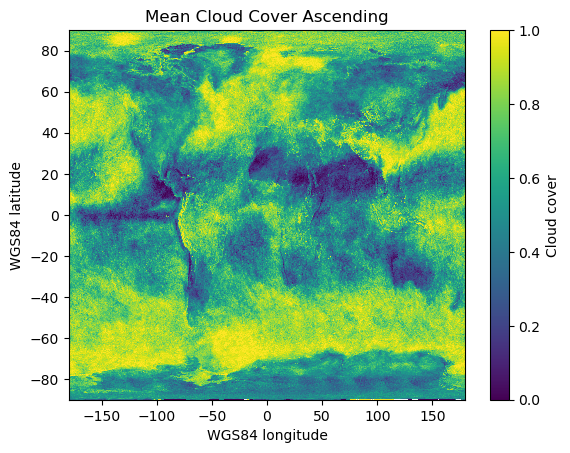

In [139]:
da_cloud.mean(dim="time").plot(cbar_kwargs={"label": "Cloud cover"})
pyplot.title("Mean Cloud Cover Ascending")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

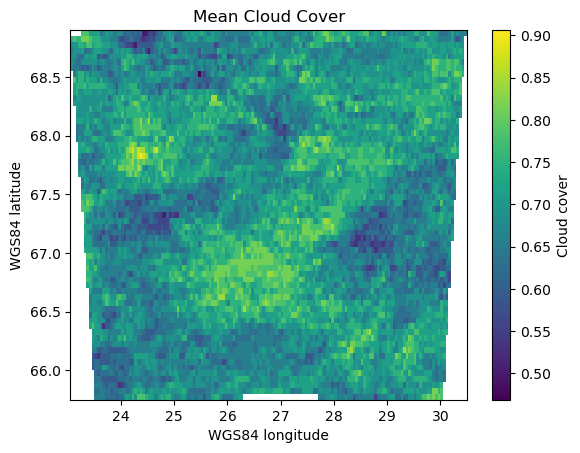

In [153]:
clipped_cloud.mean(dim="time").plot(cbar_kwargs={"label": "Cloud cover"})
pyplot.title("Mean Cloud Cover")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

In [13]:
clipped_cloud_mean = clipped_cloud.mean(dim="time")

## Remove outliers from SCFV

In [14]:
da_SCFV = ds_SCFV["scfv"]

In [15]:
da_SCFV_original = da_SCFV

In [16]:
da_SCFV_mask = (da_SCFV <= 100)

In [17]:
da_SCFV = da_SCFV * da_SCFV_mask 

## Plot SCFV

<Axes: >

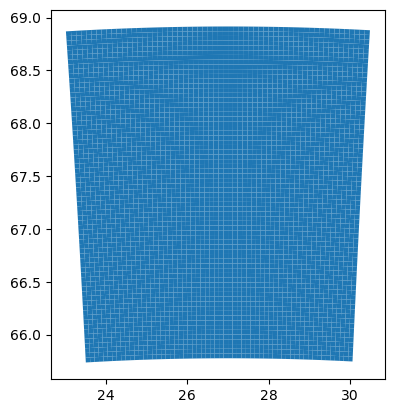

In [10]:
area.plot()

In [20]:
type(area)

geopandas.geodataframe.GeoDataFrame

In [18]:
da_SCFV = da_SCFV.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_SCFV = da_SCFV.rio.write_crs("EPSG:4326")

clipped_SCFV = da_SCFV.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

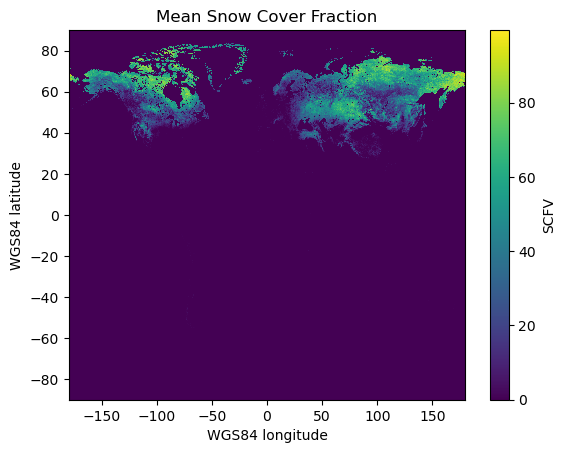

In [134]:
da_SCFV.mean(dim="time").plot(cbar_kwargs={"label": "SCFV"})
pyplot.title("Mean Snow Cover Fraction")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

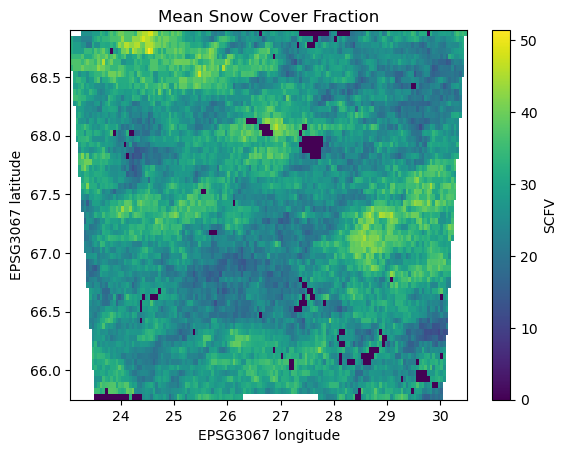

In [86]:
clipped_SCFV.mean(dim="time").plot(cbar_kwargs={"label": "SCFV"})
pyplot.title("Mean Snow Cover Fraction")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")
pyplot.show()

In [19]:
clipped_SCFV_mean = clipped_SCFV.mean(dim="time")

In [20]:
clipped_3067_SCFV = clipped_SCFV.rio.reproject("EPSG:3067")

In [20]:
left = 340000.0
right = 640000.0
bottom = 7300000.0
top = 7640000.0

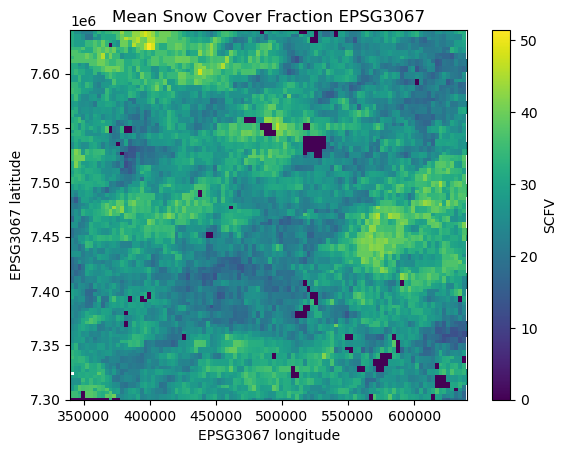

In [85]:
clipped_3067_SCFV.mean(dim="time").plot(cbar_kwargs={"label": "SCFV"})

pyplot.xlim(left, right)
pyplot.ylim(bottom, top)

pyplot.title("Mean Snow Cover Fraction EPSG3067")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")

pyplot.show()

# Mask reflectance data

In [21]:
da_refl_asc = ds_refl["refl_vis006_asc"]

In [22]:
da_refl_desc = ds_refl["refl_vis006_desc"]

In [23]:
da_refl_original_asc = da_refl_asc

In [24]:
da_refl_original_desc = da_refl_desc

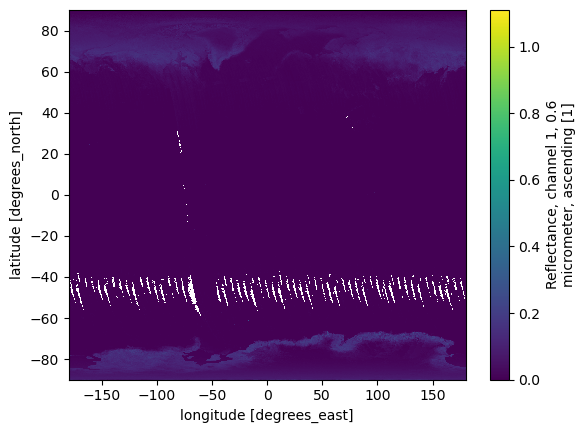

In [109]:
da_refl_original_asc.mean(dim="time").plot()

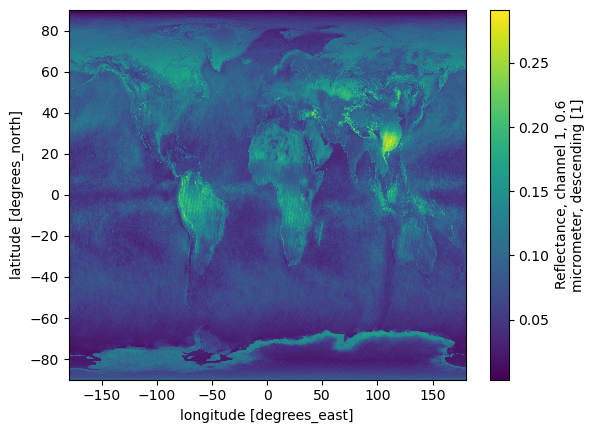

In [110]:
da_refl_original_desc.mean(dim="time").plot()

## Cloud mask

In [25]:
cloud_mask = (da_cloud <= 0.5)

In [25]:
type(cloud_mask.dtype
    )

numpy.dtypes.BoolDType

In [18]:
# Check what the mask looks like
print("True values in mask:", cloud_mask.sum().values)
print("False values in mask:", (~cloud_mask).sum().values)

True values in mask: 340742270
False values in mask: 851577730


In [26]:
cloud_values = da_cloud * cloud_mask

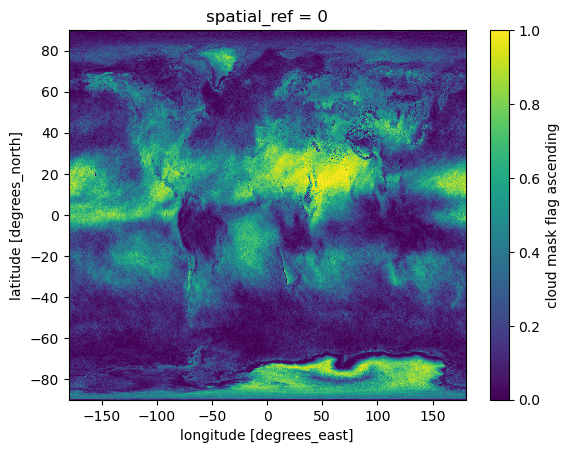

In [35]:
cloud_mask.mean(dim="time").plot()
pyplot.title("Cloud mask")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

In [27]:
da_refl_masked_asc = da_refl_asc * cloud_mask

In [28]:
da_refl_masked_desc = da_refl_desc * cloud_mask

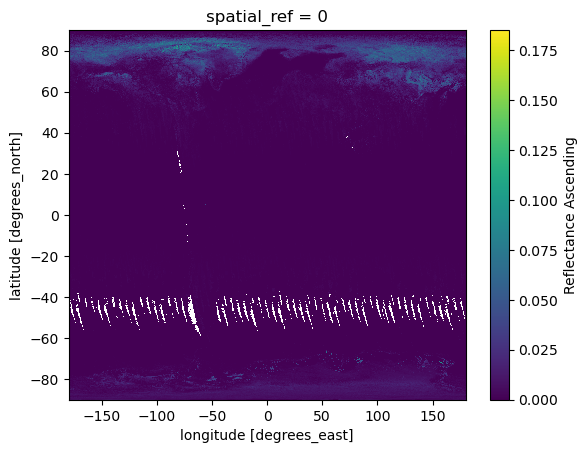

In [102]:
da_refl_masked_asc.mean(dim="time").plot(cbar_kwargs={"label": "Reflectance Ascending"})

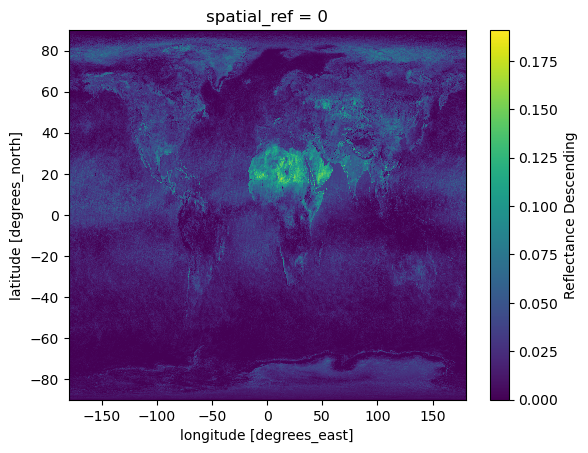

In [103]:
da_refl_masked_desc.mean(dim="time").plot(cbar_kwargs={"label": "Reflectance Descending"})

## SCFV outliers mask

In [29]:
SCFV_mask_outliers = (da_SCFV_original <= 100)

In [44]:
# Check what the mask looks like
print("True values in mask:", SCFV_mask_outliers.sum().values)
print("False values in mask:", (~SCFV_mask_outliers).sum().values)

True values in mask: 139025097
False values in mask: 1053294903


In [30]:
SCFV_values = da_SCFV_original * SCFV_mask_outliers

In [31]:
da_refl_masked_asc = da_refl_masked_asc * SCFV_mask_outliers

In [32]:
da_refl_masked_desc = da_refl_masked_desc * SCFV_mask_outliers

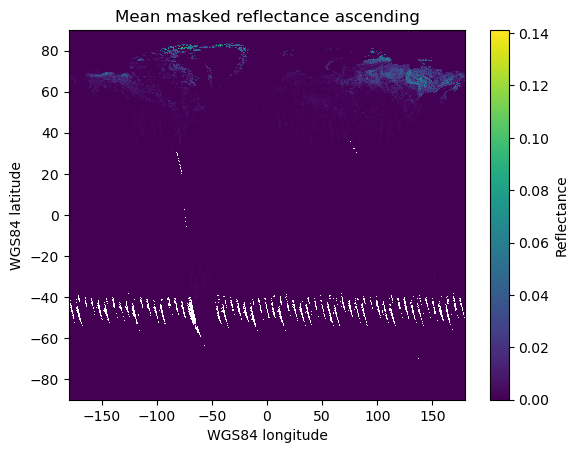

In [107]:
da_refl_masked_asc.mean(dim="time").plot(cbar_kwargs={"label": "Reflectance"})
pyplot.title("Mean masked reflectance ascending")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

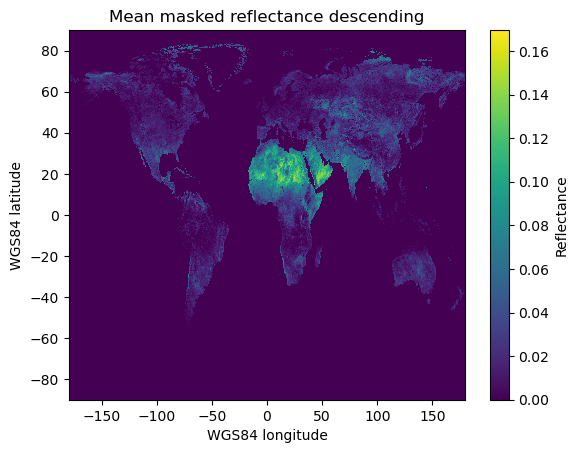

In [32]:
da_refl_masked_desc.mean(dim="time").plot(cbar_kwargs={"label": "Reflectance"})
pyplot.title("Mean masked reflectance descending")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

## Angles mask

In [33]:
sunzen_asc = (ds_angle["sunzen_asc"] <= 85)

In [34]:
print(sunzen_asc.dtype)

bool


In [34]:
# Check what the mask looks like
print("True values in mask:", sunzen_asc.sum().values)
print("False values in mask:", (~sunzen_asc).sum().values)

True values in mask: 78850552
False values in mask: 1113469448


In [34]:
sunzen_asc_values = ds_angle["sunzen_asc"] * sunzen_asc

In [35]:
sunzen_desc = (ds_angle["sunzen_desc"] <= 85)

In [36]:
sunzen_desc_values = ds_angle["sunzen_desc"] * sunzen_asc

In [37]:
satzen_asc = (ds_angle["satzen_asc"] <= 45)

In [38]:
satzen_asc_values = ds_angle["satzen_asc"] * satzen_asc

In [39]:
satzen_desc = (ds_angle["satzen_desc"] <= 45)

In [40]:
satzen_desc_values = ds_angle["satzen_desc"] * satzen_desc

Kemijoki angles

In [67]:
da_sunzen_asc_values = sunzen_asc_values.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_sunzen_asc_values = da_sunzen_asc_values.rio.write_crs("EPSG:4326")

clipped_sunzen_asc = da_sunzen_asc_values.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

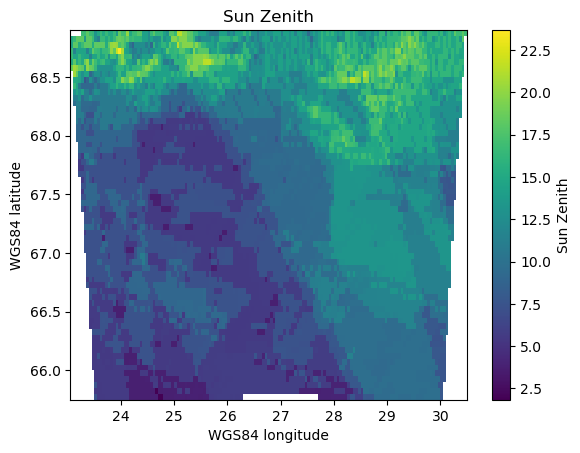

In [89]:
clipped_sunzen_asc.mean(dim="time").plot(cbar_kwargs={"label": "Sun Zenith"})
pyplot.title("Sun Zenith")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

In [41]:
da_sunzen_desc_values = sunzen_desc_values.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_sunzen_desc_values = da_sunzen_desc_values.rio.write_crs("EPSG:4326")

clipped_sunzen_desc = da_sunzen_desc_values.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [42]:
da_satzen_asc_values = satzen_asc_values.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_satzen_asc_values = da_satzen_asc_values.rio.write_crs("EPSG:4326")

clipped_satzen_asc = da_satzen_asc_values.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [43]:
da_satzen_desc_values = satzen_desc_values.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_satzen_desc_values = da_satzen_desc_values.rio.write_crs("EPSG:4326")

clipped_satzen_desc = da_satzen_desc_values.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

Combine reflectance masked data

In [44]:
refl_satzen_asc = satzen_asc * da_refl_masked_asc

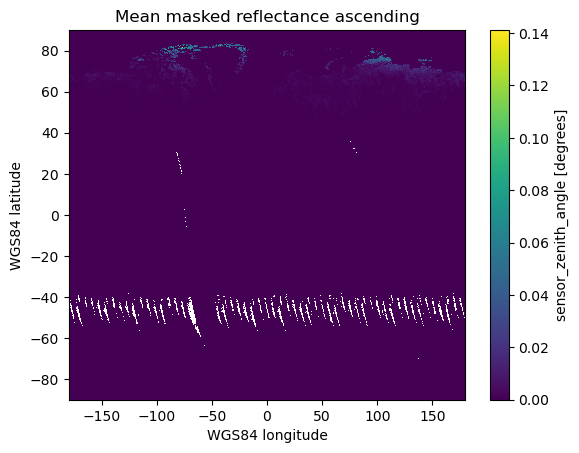

In [50]:
refl_satzen_asc.mean(dim="time").plot()
pyplot.title("Mean masked reflectance ascending")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

In [45]:
refl_satzen_desc = satzen_desc * da_refl_masked_desc

In [46]:
refl_sunzen_asc = sunzen_asc * da_refl_masked_asc

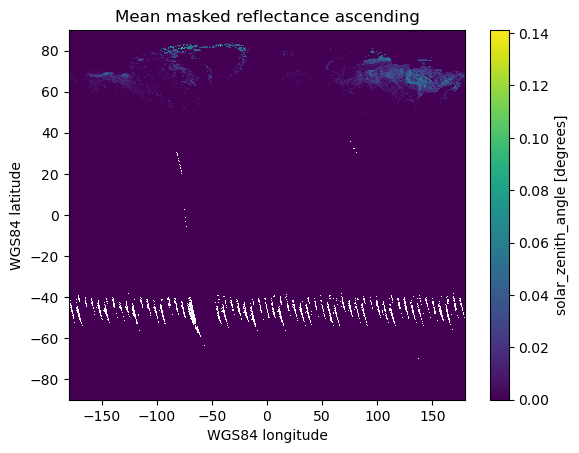

In [51]:
refl_sunzen_asc.mean(dim="time").plot()
pyplot.title("Mean masked reflectance ascending")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")
pyplot.show()

In [47]:
refl_sunzen_desc = sunzen_desc * da_refl_masked_desc

In [48]:
da_refl_masked_asc = xr.merge([refl_sunzen_asc.rename("sunzen_asc"), refl_satzen_asc.rename("satzen_asc")], compat="equals").to_array().squeeze()

In [49]:
da_refl_masked_desc = xr.merge([refl_sunzen_desc.rename("sunzen_desc"), refl_satzen_desc.rename("satzen_desc")], compat="equals").to_array().squeeze()

Plot data

In [53]:
da_refl_masked_desc

<xarray.DataArray (variable: 2, time: 46, lat: 3600, lon: 7200)> Size: 19GB
dask.array<stack, shape=(2, 46, 3600, 7200), dtype=float64, chunksize=(1, 1, 1200, 2400), chunktype=numpy.ndarray>
Coordinates:
  * variable     (variable) object 16B 'sunzen_desc' 'satzen_desc'
  * time         (time) datetime64[ns] 368B 2000-02-15 2000-02-16 ... 2000-03-31
  * lat          (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.88 89.93 89.97
  * lon          (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    standard_name:        sensor_zenith_angle
    units:                degrees
    valid_min:            0
    valid_range:          [  0 254]
    actual_range:         [  0 100]
    grid_mapping:         spatial_ref
    ancillary_variables:  scfv_unc

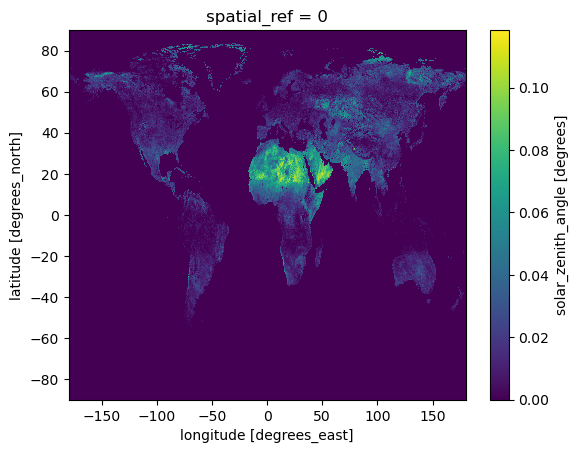

In [60]:
((da_refl_masked_desc.sel(variable="sunzen_desc") + da_refl_masked_desc.sel(variable="satzen_desc")) / 2).mean(dim="time").plot.pcolormesh(x="lon", y="lat")

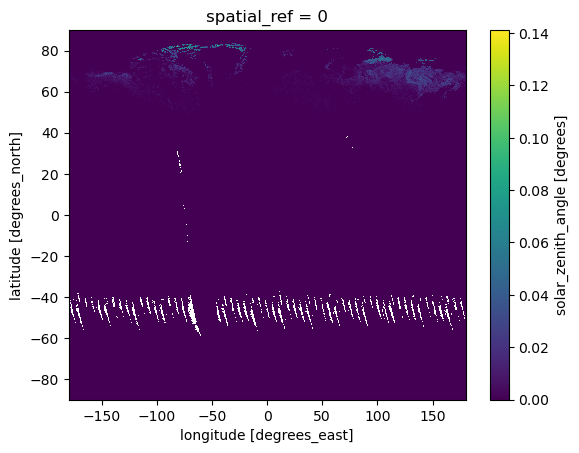

In [56]:
((da_refl_masked_asc.sel(variable="sunzen_asc") + da_refl_masked_asc.sel(variable="satzen_asc")) / 2).mean(dim="time").plot.pcolormesh(x="lon", y="lat")

In [50]:
da_refl_masked_asc_mean = ((da_refl_masked_asc.sel(variable="sunzen_asc") + da_refl_masked_asc.sel(variable="satzen_asc")) / 2).mean(dim="time")

In [51]:
da_refl_masked_desc_mean = ((da_refl_masked_desc.sel(variable="sunzen_desc") + da_refl_masked_desc.sel(variable="satzen_desc")) / 2).mean(dim="time")

## Plot Kemijoki reflectancies

In [52]:
da_refl_desc_coord = da_refl_masked_desc_mean.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_refl_desc_coord = da_refl_desc_coord.rio.write_crs("EPSG:4326")

clipped_refl_desc = da_refl_desc_coord.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [53]:
clipped_refl_desc_orig = clipped_refl_desc

In [54]:
da_refl_asc = da_refl_masked_asc_mean.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_refl_asc = da_refl_asc.rio.write_crs("EPSG:4326")

clipped_refl_asc = da_refl_asc.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [55]:
clipped_refl_asc_orig = clipped_refl_asc

In [56]:
clipped_3067_refl_desc = clipped_refl_desc.rio.reproject("EPSG:3067")

In [57]:
clipped_3067_refl_asc = clipped_refl_asc.rio.reproject("EPSG:3067")

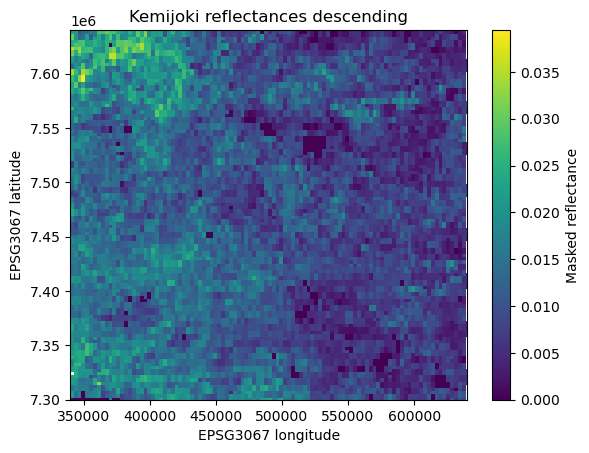

In [66]:
clipped_3067_refl_desc.plot.pcolormesh(cbar_kwargs={"label": "Masked reflectance"})
pyplot.xlim(left, right)
pyplot.ylim(bottom, top)
pyplot.title("Kemijoki reflectances descending")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")
pyplot.show()

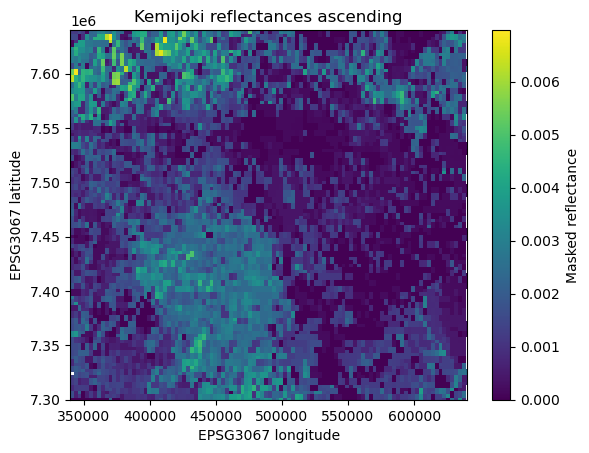

In [68]:
clipped_3067_refl_asc.plot.pcolormesh(cbar_kwargs={"label": "Masked reflectance"})
pyplot.xlim(left, right)
pyplot.ylim(bottom, top)
pyplot.title("Kemijoki reflectances ascending")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")
pyplot.show()

In [100]:
clipped_3067_refl_asc

<xarray.DataArray (y: 121, x: 116)> Size: 112kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(121, 116))
Coordinates:
  * y            (y) float64 968B 7.647e+06 7.644e+06 ... 7.298e+06 7.295e+06
  * x            (x) float64 928B 3.205e+05 3.235e+05 ... 6.552e+05 6.581e+05
    spatial_ref  int64 8B 0
Attributes:
    standard_name:        solar_zenith_angle
    units:                degrees
    valid_min:            0
    valid_range:          [  0 254]
    actual_range:         [  0 100]
    ancillary_variables:  scfv_unc
    _FillValue:           nan

# Calculate transmissivity with SCAmod method

t2 = (obs_refl * forest_refl) / (snow_refl - forest_refl)

Reference reflectancies from ATBD

𝝆𝝀,𝒇𝒐𝒓𝒆𝒔𝒕 0.08 𝝆𝝀,𝒈𝒓𝒐𝒖𝒏𝒅 0.10 𝝆𝝀,𝒔𝒏𝒐𝒘 0.65

In [58]:
t2_desc = (da_refl_masked_desc_mean* 0.08) / (0.65 - 0.08)

In [59]:
t2_asc = (da_refl_masked_asc_mean* 0.08) / (0.65 - 0.08)

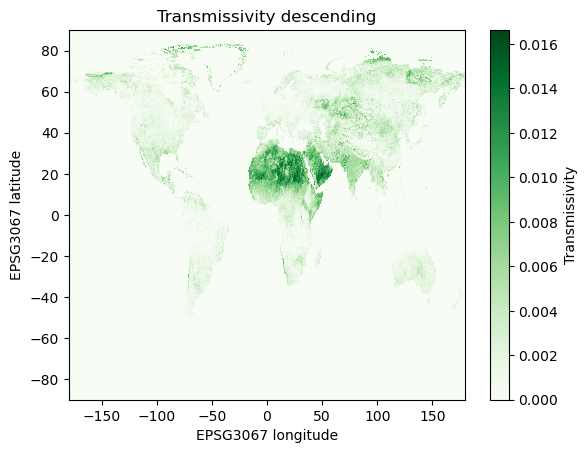

In [76]:
t2_desc.plot(cmap="Greens", cbar_kwargs={"label": "Transmissivity"})
pyplot.title("Transmissivity descending")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")
pyplot.show()

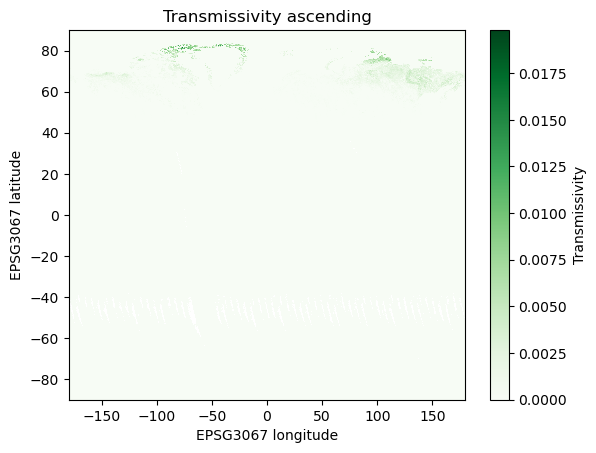

In [77]:
t2_asc.plot(cmap="Greens", cbar_kwargs={"label": "Transmissivity"})
pyplot.title("Transmissivity ascending")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")
pyplot.show()

## Plot Kemijoki transmissivities

In [60]:
clipped_t2_desc = t2_desc.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [61]:
clipped_t2_asc = t2_asc.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [62]:
clipped_3067_t2_desc = clipped_t2_desc.rio.reproject("EPSG:3067")

In [63]:
clipped_3067_t2_asc = clipped_t2_asc.rio.reproject("EPSG:3067")

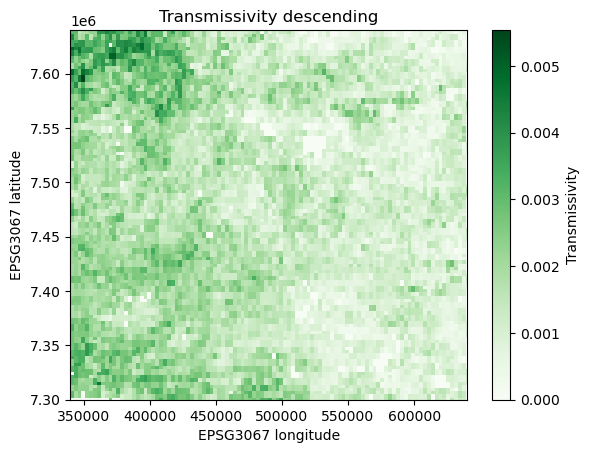

In [63]:
clipped_3067_t2_desc.plot(cmap="Greens", cbar_kwargs={"label": "Transmissivity"})
pyplot.xlim(left, right)
pyplot.ylim(bottom, top)
pyplot.title("Transmissivity descending")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")
pyplot.show()

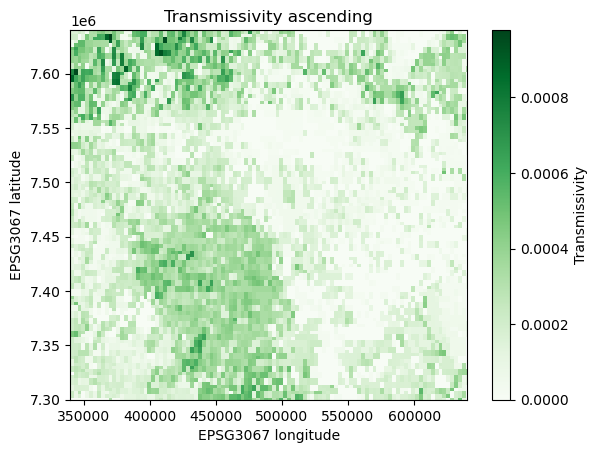

In [64]:
clipped_3067_t2_asc.plot(cmap="Greens", cbar_kwargs={"label": "Transmissivity"})
pyplot.xlim(left, right)
pyplot.ylim(bottom, top)
pyplot.title("Transmissivity ascending")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")
pyplot.show()

# Combine all data

In [64]:
ds_all_data = xr.merge([t2_desc.rename("t2_desc"), t2_asc.rename("t2_asc"), da_refl_masked_desc.rename("refl_desc"), da_refl_masked_asc.rename("refl_asc"), cloud_values.rename("cloud"), SCFV_values, sunzen_asc_values.rename("sunzen_asc"), sunzen_desc_values.rename("sunzen_desc"), satzen_asc_values.rename("satzen_asc"), satzen_desc_values.rename("satzen_desc")])

C:\Users\minttu\AppData\Local\Temp\ipykernel_14652\3443792558.py:1: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'variable' ('variable',) The recommendation is to set join explicitly for this case.
  ds_all_data = xr.merge([t2_desc.rename("t2_desc"), t2_asc.rename("t2_asc"), da_refl_masked_desc.rename("refl_desc"), da_refl_masked_asc.rename("refl_asc"), cloud_values.rename("cloud"), SCFV_values, sunzen_asc_values.rename("sunzen_asc"), sunzen_desc_values.rename("sunzen_desc"), satzen_asc_values.rename("satzen_asc"), satzen_desc_values.rename("satzen_desc")])


In [65]:
ds_all_data

<xarray.Dataset> Size: 124GB
Dimensions:      (lat: 3600, lon: 7200, time: 46, variable: 4)
Coordinates:
  * lat          (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.88 89.93 89.97
  * lon          (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
  * time         (time) datetime64[ns] 368B 2000-02-15 2000-02-16 ... 2000-03-31
  * variable     (variable) object 32B 'satzen_asc' ... 'sunzen_desc'
    spatial_ref  int64 8B 0
Data variables:
    t2_desc      (lat, lon) float64 207MB dask.array<chunksize=(1200, 2400), meta=np.ndarray>
    t2_asc       (lat, lon) float64 207MB dask.array<chunksize=(1200, 2400), meta=np.ndarray>
    refl_desc    (variable, time, lat, lon) float64 38GB dask.array<chunksize=(1, 1, 1200, 2400), meta=np.ndarray>
    refl_asc     (variable, time, lat, lon) float64 38GB dask.array<chunksize=(1, 1, 1200, 2400), meta=np.ndarray>
    cloud        (time, lat, lon) float32 5GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    scfv         (time, lat, lon) float32 5GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    sunzen_asc   (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    sunzen_desc  (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    satzen_asc   (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    satzen_desc  (time, lat, lon) float64 10GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
Attributes:
    standard_name:        solar_zenith_angle
    units:                degrees
    valid_min:            0
    valid_range:          [  0 254]
    actual_range:         [  0 100]
    grid_mapping:         spatial_ref
    ancillary_variables:  scfv_unc

In [129]:
for var in ds_all_data.data_vars:
    print(var, ds_all_data[var].dims)

t2_desc ('lat', 'lon')
t2_asc ('lat', 'lon')
refl_desc ('variable', 'time', 'lat', 'lon')
refl_asc ('variable', 'time', 'lat', 'lon')
cloud ('time', 'lat', 'lon')
scfv ('time', 'lat', 'lon')
sunzen_asc ('time', 'lat', 'lon')
sunzen_desc ('time', 'lat', 'lon')
satzen_asc ('time', 'lat', 'lon')
satzen_desc ('time', 'lat', 'lon')


## Combine Kemijoki data

In [68]:
ds_Kemijoki_data = xr.merge([t2_desc.rename("clipped_t2_desc"), t2_asc.rename("clipped_t2_asc"), clipped_refl_desc_orig.rename("refl_desc"), clipped_refl_asc_orig.rename("refl_asc"), clipped_cloud.rename("cloud"), clipped_SCFV, clipped_satzen_desc.rename("satzen_desc"), clipped_sunzen_desc.rename("sunzen_desc"), clipped_satzen_asc.rename("satzen_asc"), clipped_sunzen_asc.rename("sunzen_asc")])

C:\Users\minttu\AppData\Local\Temp\ipykernel_14652\387042441.py:1: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'lat' ('lat',) The recommendation is to set join explicitly for this case.
  ds_Kemijoki_data = xr.merge([t2_desc.rename("clipped_t2_desc"), t2_asc.rename("clipped_t2_asc"), clipped_refl_desc_orig.rename("refl_desc"), clipped_refl_asc_orig.rename("refl_asc"), clipped_cloud.rename("cloud"), clipped_SCFV, clipped_satzen_desc.rename("satzen_desc"), clipped_sunzen_desc.rename("sunzen_desc"), clipped_satzen_asc.rename("satzen_asc"), clipped_sunzen_asc.rename("sunzen_asc")])
C:\Users\minttu\AppData\Local\Temp\ipykernel_14652\387042441.py:1: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to 

In [137]:
ds_Kemijoki_data

<xarray.Dataset> Size: 29GB
Dimensions:          (lat: 3600, lon: 7200, time: 46)
Coordinates:
  * lat              (lat) float64 29kB -89.97 -89.93 -89.88 ... 89.93 89.97
  * lon              (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 180.0
  * time             (time) datetime64[ns] 368B 2000-02-15 ... 2000-03-31
    spatial_ref      int64 8B 0
Data variables:
    clipped_t2_desc  (lat, lon) float32 104MB dask.array<chunksize=(1200, 2400), meta=np.ndarray>
    clipped_t2_asc   (lat, lon) float32 104MB dask.array<chunksize=(1200, 2400), meta=np.ndarray>
    refl_desc        (lat, lon) float32 104MB dask.array<chunksize=(63, 149), meta=np.ndarray>
    refl_asc         (lat, lon) float32 104MB dask.array<chunksize=(63, 149), meta=np.ndarray>
    cloud            (time, lat, lon) float32 5GB dask.array<chunksize=(1, 63, 149), meta=np.ndarray>
    scfv             (time, lat, lon) float32 5GB dask.array<chunksize=(1, 63, 149), meta=np.ndarray>
    satzen_desc      (time, lat, lon) float32 5GB dask.array<chunksize=(1, 63, 149), meta=np.ndarray>
    sunzen_desc      (time, lat, lon) float32 5GB dask.array<chunksize=(1, 63, 149), meta=np.ndarray>
    satzen_asc       (time, lat, lon) float32 5GB dask.array<chunksize=(1, 63, 149), meta=np.ndarray>
    sunzen_asc       (time, lat, lon) float32 5GB dask.array<chunksize=(1, 63, 149), meta=np.ndarray>
Attributes:
    standard_name:        solar_zenith_angle
    units:                degrees
    valid_min:            0
    valid_range:          [  0 254]
    actual_range:         [  0 100]
    grid_mapping:         spatial_ref
    ancillary_variables:  scfv_unc

Save dataset

In [136]:
ds_Kemijoki_data.isel(time=0).load().to_netcdf("Kemijoki_data.nc", engine="h5netcdf", mode="w")

for t in range(1, ds_Kemijoki_data.sizes["time"]):
    ds_Kemijoki_data.isel(time=[t]).load().to_netcdf(
        "Kemijoki_data.nc", engine="h5netcdf", mode="a"
    )
    if t % 20 == 0:
        print(f"{t} timesteps written")

RuntimeError: NetCDF: HDF error

In [ ]:
ds_Kemijoki_data.to_netcdf()

Show info

In [122]:
ds_Kemijoki_data.coords

Coordinates:
  * lat          (lat) float64 29kB -89.97 -89.93 -89.88 ... 89.88 89.93 89.97
  * lon          (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
  * time         (time) datetime64[ns] 368B 2000-02-15 2000-02-16 ... 2000-03-31
    spatial_ref  int64 8B 0

In [123]:
for var in ds_Kemijoki_data.data_vars:
    print(var, ds_Kemijoki_data[var].dims)

clipped_t2_desc ('lat', 'lon')
clipped_t2_asc ('lat', 'lon')
refl_desc ('lat', 'lon')
refl_asc ('lat', 'lon')
cloud ('time', 'lat', 'lon')
scfv ('time', 'lat', 'lon')
satzen_desc ('time', 'lat', 'lon')
sunzen_desc ('time', 'lat', 'lon')
satzen_asc ('time', 'lat', 'lon')
sunzen_asc ('time', 'lat', 'lon')


## Plot global angles and reflectancies

t2 ha no time dimension

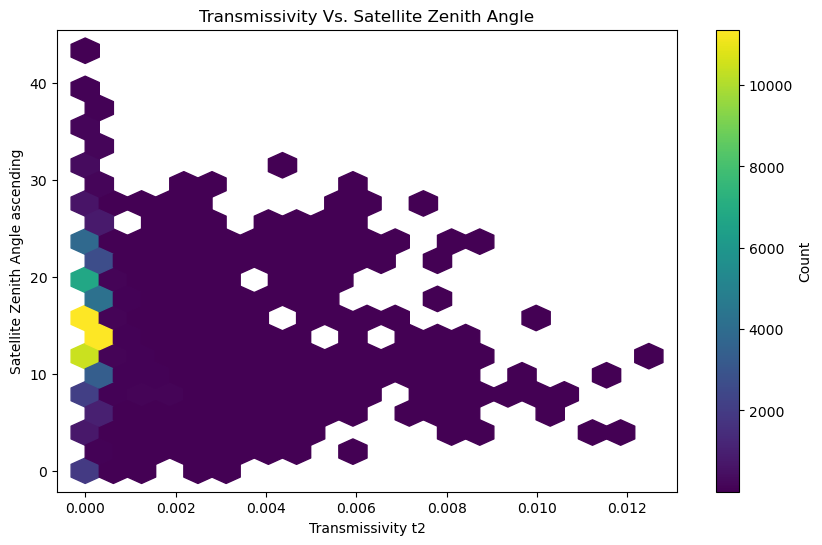

In [108]:
step = 20  # subsample before computing mean for speed

t2 = ds_all_data["t2_asc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["t2_asc"].dims}
)
satzen = ds_all_data["satzen_asc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["satzen_asc"].dims if dim != "time"}
).mean(dim="time")

x = t2.values.flatten()
y = satzen.values.flatten()

mask = ~np.isnan(x) & ~np.isnan(y)
x, y = x[mask], y[mask]

fig, ax = pyplot.subplots(figsize=(10, 6))
hb = ax.hexbin(x, y, gridsize=20, cmap="viridis", mincnt=1)
ax.set_title("Transmissivity Vs. Satellite Zenith Angle")
ax.set_xlabel("Transmissivity t2")
ax.set_ylabel("Satellite Zenith Angle ascending")
fig.colorbar(hb, ax=ax, label="Count")
pyplot.show()

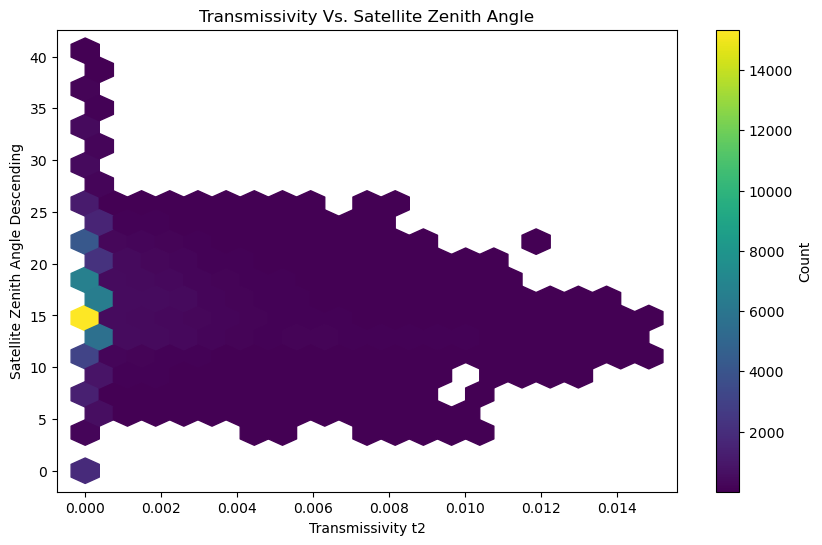

In [104]:
step = 20  # subsample before computing mean for speed

t2 = ds_all_data["t2_desc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["t2_desc"].dims}
)
satzen = ds_all_data["satzen_desc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["satzen_desc"].dims if dim != "time"}
).mean(dim="time")

x = t2.values.flatten()
y = satzen.values.flatten()

mask = ~np.isnan(x) & ~np.isnan(y)
x, y = x[mask], y[mask]

fig, ax = pyplot.subplots(figsize=(10, 6))
hb = ax.hexbin(x, y, gridsize=20, cmap="viridis", mincnt=1)
ax.set_title("Transmissivity Vs. Satellite Zenith Angle")
ax.set_xlabel("Transmissivity t2")
ax.set_ylabel("Satellite Zenith Angle Descending")
fig.colorbar(hb, ax=ax, label="Count")
pyplot.show()

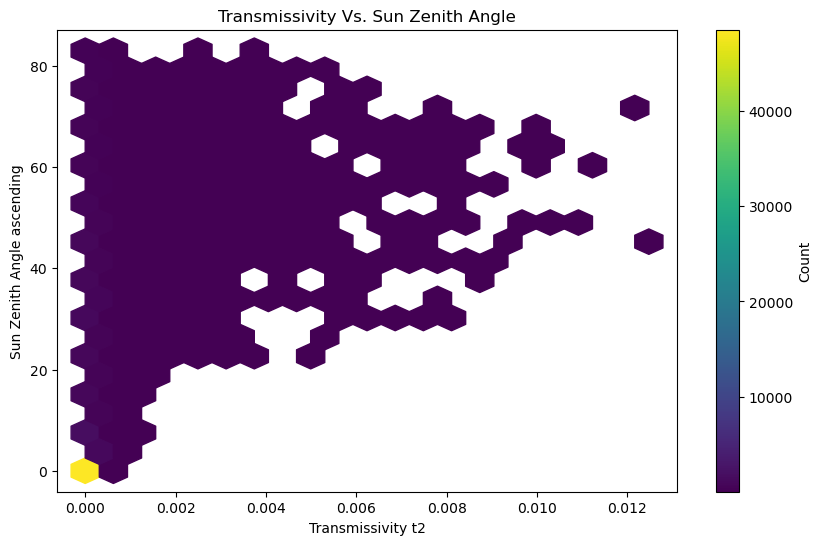

In [106]:
step = 20  # subsample before computing mean for speed

t2 = ds_all_data["t2_asc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["t2_asc"].dims}
)
satzen = ds_all_data["sunzen_asc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["sunzen_asc"].dims if dim != "time"}
).mean(dim="time")

x = t2.values.flatten()
y = satzen.values.flatten()

mask = ~np.isnan(x) & ~np.isnan(y)
x, y = x[mask], y[mask]

fig, ax = pyplot.subplots(figsize=(10, 6))
hb = ax.hexbin(x, y, gridsize=20, cmap="viridis", mincnt=1)
ax.set_title("Transmissivity Vs. Sun Zenith Angle")
ax.set_xlabel("Transmissivity t2")
ax.set_ylabel("Sun Zenith Angle ascending")
fig.colorbar(hb, ax=ax, label="Count")
pyplot.show()

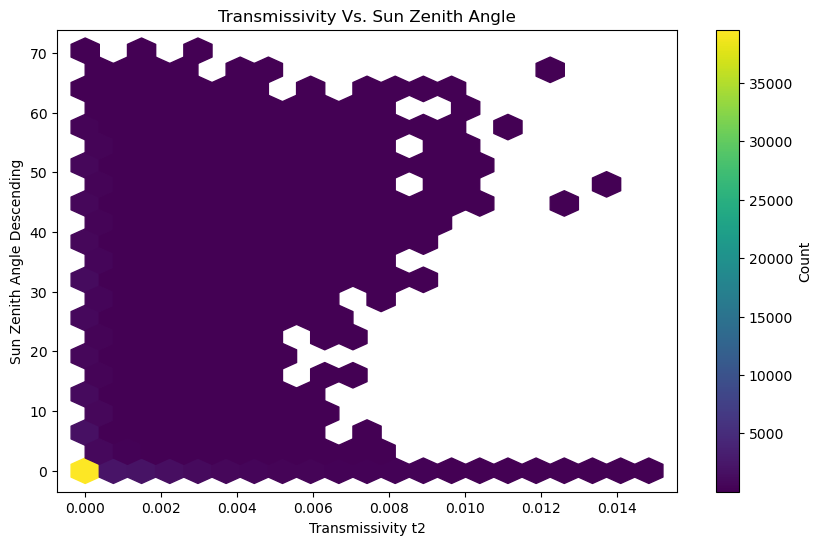

In [107]:
step = 20  # subsample before computing mean for speed

t2 = ds_all_data["t2_desc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["t2_desc"].dims}
)
satzen = ds_all_data["sunzen_desc"].isel(
    {dim: slice(None, None, step) for dim in ds_all_data["sunzen_desc"].dims if dim != "time"}
).mean(dim="time")

x = t2.values.flatten()
y = satzen.values.flatten()

mask = ~np.isnan(x) & ~np.isnan(y)
x, y = x[mask], y[mask]

fig, ax = pyplot.subplots(figsize=(10, 6))
hb = ax.hexbin(x, y, gridsize=20, cmap="viridis", mincnt=1)
ax.set_title("Transmissivity Vs. Sun Zenith Angle")
ax.set_xlabel("Transmissivity t2")
ax.set_ylabel("Sun Zenith Angle Descending")
fig.colorbar(hb, ax=ax, label="Count")
pyplot.show()

## Plot backwards or forwards scattering

## Plot Kemijoki angles and reflectancies